# Deep Learning Assignment 01 - Section B, Question 1

**Name:** `Naina Awan` | **Roll no:** `23F-0777` | **Batch:** `23`

## 1. Imports and seed

In [1]:
import os
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from scipy.ndimage import rotate, gaussian_filter
from matplotlib.patches import Patch
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

tf.get_logger().setLevel('ERROR')

SEED = 42
SEEDS = [0, 1, 2]
MAX_EPOCHS = 60
BATCH_SIZE = 25

tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

print("Seed:", SEED, "| Run seeds:", SEEDS)
print("TensorFlow:", tf.__version__, "| NumPy:", np.__version__)

Seed: 42 | Run seeds: [0, 1, 2]
TensorFlow: 2.21.0 | NumPy: 2.1.3


## 2. Making the data files

In [2]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

(X_all, y_all), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()
y_all = y_all.flatten()
y_test = y_test.flatten()

rs = np.random.RandomState(SEED)
small_idx = []
for c in range(10):
    idx = np.where(y_all == c)[0]
    small_idx += list(rs.choice(idx, 50, replace=False))

np.savez_compressed("train_small.npz", x=X_all[small_idx], y=y_all[small_idx])
np.savez_compressed("clean_test.npz", x=X_test, y=y_test)
print("Saved train_small.npz and clean_test.npz")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2374s 14us/step
Saved train_small.npz and clean_test.npz


In [3]:
def hidden_corruption(img, rs):
    if rs.rand() < 0.5:
        if rs.rand() < 0.5:
            gray = img.mean(axis=2, keepdims=True)
            img = np.repeat(gray, 3, axis=2)
        else:
            img = img[:, :, rs.permutation(3)]
    return img

def make_shifted(img, rs):
    img = img.astype('float32')
    img = rotate(img, rs.uniform(-25, 25), reshape=False, order=1, mode='constant', cval=0)
    img = img * rs.uniform(0.5, 1.5)
    img = (img - img.mean()) * rs.uniform(0.5, 1.5) + img.mean()
    if rs.rand() < 0.5:
        s = rs.uniform(0.5, 1.5)
        img = gaussian_filter(img, sigma=(s, s, 0))
    img = img + rs.normal(0, rs.uniform(0, 20), img.shape)
    img = hidden_corruption(img, rs)
    h = rs.randint(8, 33)
    w = min(32, 256 // h)
    top = rs.randint(0, 32 - h + 1)
    left = rs.randint(0, 32 - w + 1)
    img[top:top + h, left:left + w, :] = 0
    return np.clip(img, 0, 255).astype('uint8')

rs = np.random.RandomState(123)
X_shifted = np.array([make_shifted(img, rs) for img in X_test])

rs = np.random.RandomState(456)
X_hidden = np.array([hidden_corruption(img.astype('float32'), rs).astype('uint8') for img in X_test])

np.savez_compressed("shifted_test.npz", x=X_shifted, y=y_test)
np.savez_compressed("hidden_only_test.npz", x=X_hidden, y=y_test)
print("Saved shifted_test.npz and hidden_only_test.npz")

Saved shifted_test.npz and hidden_only_test.npz


## 3. Split into 400 train and 100 validation

In [4]:
small = np.load("train_small.npz")
clean = np.load("clean_test.npz")
shifted = np.load("shifted_test.npz")
hidden = np.load("hidden_only_test.npz")

X_small, y_small = small["x"], small["y"]
X_clean_test, y_clean_test = clean["x"], clean["y"]
X_shifted_test, y_shifted_test = shifted["x"], shifted["y"]
X_hidden_test, y_hidden_test = hidden["x"], hidden["y"]

X_train, X_val, y_train, y_val = train_test_split(
    X_small, y_small, test_size=100, stratify=y_small, random_state=SEED)

X_train, X_val = X_train.astype('float32'), X_val.astype('float32')
X_clean_test = X_clean_test.astype('float32')
X_shifted_test = X_shifted_test.astype('float32')
X_hidden_test = X_hidden_test.astype('float32')

y_train_oh = tf.keras.utils.to_categorical(y_train, 10).astype('float32')
y_val_oh = tf.keras.utils.to_categorical(y_val, 10).astype('float32')

print("Train:", X_train.shape, "| Validation:", X_val.shape)
print("Clean test:", X_clean_test.shape, "| Shifted test:", X_shifted_test.shape)
print("Images per class in train:", np.bincount(y_train))
print("Images per class in validation:", np.bincount(y_val))

Train: (400, 32, 32, 3) | Validation: (100, 32, 32, 3)
Clean test: (10000, 32, 32, 3) | Shifted test: (10000, 32, 32, 3)
Images per class in train: [40 40 40 40 40 40 40 40 40 40]
Images per class in validation: [10 10 10 10 10 10 10 10 10 10]


## 4 Images

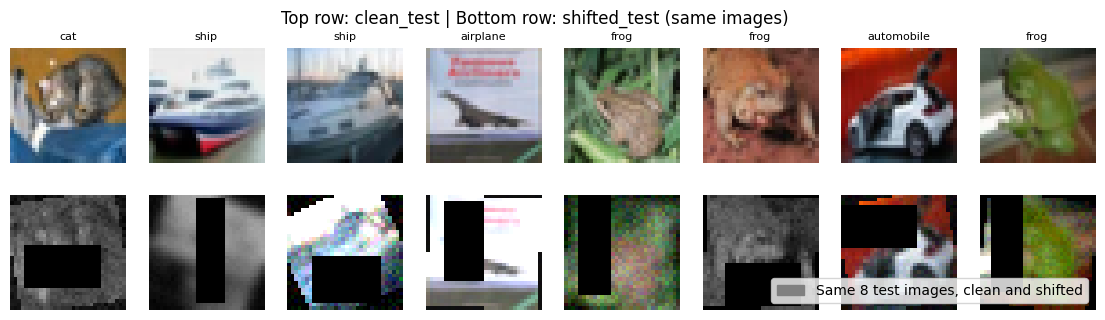

In [5]:
plt.figure(figsize=(14, 3.5))
for i in range(8):
    plt.subplot(2, 8, i + 1)
    plt.imshow(X_clean_test[i].astype('uint8'))
    plt.title(class_names[y_clean_test[i]], fontsize=8)
    plt.axis('off')
    plt.subplot(2, 8, i + 9)
    plt.imshow(X_shifted_test[i].astype('uint8'))
    plt.axis('off')
plt.suptitle("Top row: clean_test | Bottom row: shifted_test (same images)")
plt.legend(handles=[Patch(color='gray', label='Same 8 test images, clean and shifted')], loc='lower right')
plt.show()

## 5. Augmentation layers

In [6]:
class RandomBlur(layers.Layer):
    def __init__(self, p=0.3, **kwargs):
        super().__init__(**kwargs)
        self.p = p

    def call(self, x, training=None):
        if not training:
            return x
        blurred = tf.nn.avg_pool2d(x, 3, 1, 'SAME')
        use = tf.random.uniform([tf.shape(x)[0], 1, 1, 1]) < self.p
        return tf.where(use, blurred, x)

class RandomNoise(layers.Layer):
    def __init__(self, std=12.0, p=0.4, **kwargs):
        super().__init__(**kwargs)
        self.std = std
        self.p = p

    def call(self, x, training=None):
        if not training:
            return x
        noise = tf.random.normal(tf.shape(x), stddev=self.std)
        use = tf.cast(tf.random.uniform([tf.shape(x)[0], 1, 1, 1]) < self.p, tf.float32)
        return tf.clip_by_value(x + noise * use, 0.0, 255.0)

class Cutout(layers.Layer):
    def __init__(self, p=0.5, low=8, high=18, **kwargs):
        super().__init__(**kwargs)
        self.p = p
        self.low = low
        self.high = high

    def call(self, x, training=None):
        if not training:
            return x
        n = tf.shape(x)[0]
        size = tf.random.uniform([], self.low, self.high + 1, dtype=tf.int32)
        top = tf.random.uniform([n, 1, 1], 0, 33 - size, dtype=tf.int32)
        left = tf.random.uniform([n, 1, 1], 0, 33 - size, dtype=tf.int32)
        rows = tf.reshape(tf.range(32), [1, 32, 1])
        cols = tf.reshape(tf.range(32), [1, 1, 32])
        mask = (rows >= top) & (rows < top + size) & (cols >= left) & (cols < left + size)
        mask = mask & (tf.random.uniform([n, 1, 1]) < self.p)
        return tf.where(mask[..., None], tf.zeros_like(x), x)

class RandomColor(layers.Layer):
    def __init__(self, p_gray=0.1, p_swap=0.1, **kwargs):
        super().__init__(**kwargs)
        self.p_gray = p_gray
        self.p_swap = p_swap

    def call(self, x, training=None):
        if not training:
            return x
        r = tf.random.uniform([tf.shape(x)[0], 1, 1, 1])
        gray = tf.reduce_mean(x, axis=-1, keepdims=True) * tf.ones_like(x)
        swapped = tf.reverse(x, axis=[-1])
        x = tf.where(r < self.p_gray, gray, x)
        return tf.where((r >= self.p_gray) & (r < self.p_gray + self.p_swap), swapped, x)

def get_augmentation(cfg):
    aug = []
    if cfg["geometric"]:
        aug += [layers.RandomFlip("horizontal"),
                layers.RandomRotation(0.07, fill_mode='constant'),
                layers.RandomTranslation(0.08, 0.08, fill_mode='constant'),
                layers.RandomZoom(0.1, fill_mode='constant')]
    if cfg["photometric"]:
        aug += [layers.RandomBrightness(0.25, value_range=(0, 255)),
                layers.RandomContrast(0.3),
                RandomBlur(),
                RandomNoise()]
    if cfg["colour"]:
        aug += [RandomColor()]
    if cfg["cutout"]:
        aug += [Cutout()]
    return aug

def build_aug(flip="horizontal", rotation=0.07, shift=0.08, zoom=0.1, bright=0.25, contrast=0.3,
              blur_p=0.3, noise_std=12.0, noise_p=0.4, gray_p=0.1, swap_p=0.1,
              cut_p=0.5, cut_low=8, cut_high=18):
    aug = []
    if flip:
        aug.append(layers.RandomFlip(flip))
    aug += [layers.RandomRotation(rotation, fill_mode='constant'),
            layers.RandomTranslation(shift, shift, fill_mode='constant'),
            layers.RandomZoom(zoom, fill_mode='constant'),
            layers.RandomBrightness(bright, value_range=(0, 255)),
            layers.RandomContrast(contrast),
            RandomBlur(blur_p),
            RandomNoise(noise_std, noise_p),
            RandomColor(gray_p, swap_p),
            Cutout(cut_p, cut_low, cut_high)]
    return aug

configs = {
    "No augmentation":            dict(geometric=0, photometric=0, colour=0, cutout=0, mixup=0, smoothing=0.0),
    "Geometric only":             dict(geometric=1, photometric=0, colour=0, cutout=0, mixup=0, smoothing=0.0),
    "Photometric only":           dict(geometric=0, photometric=1, colour=0, cutout=0, mixup=0, smoothing=0.0),
    "Geometric + photometric":    dict(geometric=1, photometric=1, colour=0, cutout=0, mixup=0, smoothing=0.0),
    "+ Cutout / Random Erasing":  dict(geometric=1, photometric=1, colour=0, cutout=1, mixup=0, smoothing=0.0),
    "+ Mixup + label smoothing":  dict(geometric=1, photometric=1, colour=0, cutout=1, mixup=1, smoothing=0.1),
    "Final model":                dict(geometric=1, photometric=1, colour=1, cutout=1, mixup=1, smoothing=0.1),
}

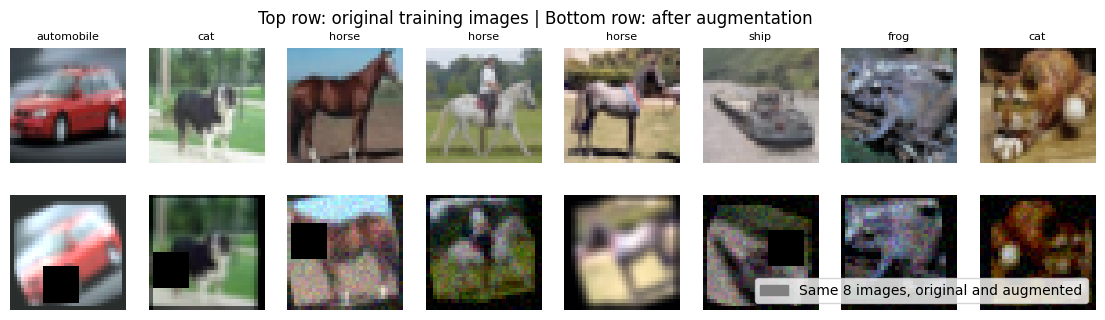

In [7]:
aug_layers = get_augmentation(configs["Final model"])
x = tf.constant(X_train[:8])
for layer in aug_layers:
    x = layer(x, training=True)

plt.figure(figsize=(14, 3.5))
for i in range(8):
    plt.subplot(2, 8, i + 1)
    plt.imshow(X_train[i].astype('uint8'))
    plt.title(class_names[y_train[i]], fontsize=8)
    plt.axis('off')
    plt.subplot(2, 8, i + 9)
    plt.imshow(np.clip(x[i].numpy(), 0, 255).astype('uint8'))
    plt.axis('off')
plt.suptitle("Top row: original training images | Bottom row: after augmentation")
plt.legend(handles=[Patch(color='gray', label='Same 8 images, original and augmented')], loc='lower right')
plt.show()

## 6. Mixup

In [8]:
def mixup(images, labels, alpha=0.2):
    n = tf.shape(images)[0]
    g1 = tf.random.gamma([n], alpha)
    g2 = tf.random.gamma([n], alpha)
    lam = g1 / (g1 + g2)
    idx = tf.random.shuffle(tf.range(n))
    lam_img = tf.reshape(lam, [-1, 1, 1, 1])
    lam_lab = tf.reshape(lam, [-1, 1])
    mixed_images = lam_img * images + (1 - lam_img) * tf.gather(images, idx)
    mixed_labels = lam_lab * labels + (1 - lam_lab) * tf.gather(labels, idx)
    return mixed_images, mixed_labels

def maybe_mixup(images, labels, p=0.5):
    return tf.cond(tf.random.uniform([]) < p,
                   lambda: mixup(images, labels),
                   lambda: (images, labels))

## 7. Inception model

In [9]:
def conv(x, filters, size, use_bn=True, l2=5e-5):
    x = layers.Conv2D(filters, size, padding='same', use_bias=not use_bn,
                      kernel_regularizer=regularizers.l2(l2))(x)
    if use_bn:
        x = layers.BatchNormalization(momentum=0.9)(x)
    return layers.Activation('relu')(x)

def inception_module(x, f1, f3_red, f3, f5_red, f5, f_pool, use_bn=True, l2=5e-5):
    branch1 = conv(x, f1, 1, use_bn, l2)
    branch3 = conv(conv(x, f3_red, 1, use_bn, l2), f3, 3, use_bn, l2)
    branch5 = conv(conv(x, f5_red, 1, use_bn, l2), f5, 5, use_bn, l2)
    pool = layers.MaxPooling2D(3, strides=1, padding='same')(x)
    branch_pool = conv(pool, f_pool, 1, use_bn, l2)
    return layers.Concatenate()([branch1, branch3, branch5, branch_pool])

def build_model(aug_layers, dropout, use_bn=True, l2=5e-5, dropout_place='fc'):
    inputs = layers.Input(shape=(32, 32, 3))
    x = inputs
    for layer in aug_layers:
        x = layer(x)
    x = layers.Rescaling(1 / 255)(x)

    x = conv(x, 48, 3, use_bn, l2)
    x = layers.MaxPooling2D(2)(x)
    if dropout_place == 'conv':
        x = layers.Dropout(dropout)(x)

    x = inception_module(x, 32, 32, 48, 16, 16, 16, use_bn, l2)
    x = layers.MaxPooling2D(2)(x)
    if dropout_place == 'conv':
        x = layers.Dropout(dropout)(x)

    x = inception_module(x, 64, 48, 96, 16, 32, 32, use_bn, l2)
    x = layers.MaxPooling2D(2)(x)
    x = inception_module(x, 96, 64, 128, 16, 32, 32, use_bn, l2)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(128, use_bias=not use_bn, kernel_regularizer=regularizers.l2(l2))(x)
    if use_bn:
        x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Activation('relu')(x)
    if dropout_place == 'fc':
        x = layers.Dropout(dropout)(x)

    outputs = layers.Dense(10, activation='softmax')(x)
    return models.Model(inputs, outputs)

test_model = build_model([], 0.3)
n_params = int(np.sum([np.prod(w.shape) for w in test_model.trainable_weights]))
test_model.summary()
print("Trainable parameters:", n_params)
assert n_params <= 1000000, "Too many parameters!"

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 32, 32, 3) │          0 │ input_layer[0][0] │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │      1,296 │ rescaling[0][0]   │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32, 32,    │        192 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 16, 16,    │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 16, 16,    │      1,536 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │        768 │ max_pooling2d[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │         64 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 16, 16,    │          0 │ max_pooling2d[0]… │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 16, 16,    │      1,536 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │     13,824 │ activation_2[0][… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 16, 16,    │      6,400 │ activation_4[0][… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │        768 │ max_pooling2d_1[

 Total params: 273,562 (1.04 MB)

 Trainable params: 271,578 (1.04 MB)

 Non-trainable params: 1,984 (7.75 KB)

Trainable parameters: 271578


## 8. Training function

In [10]:
LR = 0.001
DROPOUT = 0.3

def accuracy(model, X, y):
    pred = model.predict(X, batch_size=500, verbose=0)
    return np.mean(np.argmax(pred, axis=1) == y) * 100

def train_model(name, seed, lr=None, dropout=None, test=True, label=None, cfg=None, aug_fn=None,
                use_bn=True, l2=5e-5, dropout_place='fc', use_reduce_lr=True, use_early_stop=True, mixup_prob=None):
    cfg = configs[name] if cfg is None else cfg
    lr = LR if lr is None else lr
    dropout = DROPOUT if dropout is None else dropout
    mix_p = (0.5 if cfg["mixup"] else 0.0) if mixup_prob is None else mixup_prob

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    aug_layers = aug_fn() if aug_fn is not None else get_augmentation(cfg)
    model = build_model(aug_layers, dropout, use_bn, l2, dropout_place)
    model.compile(optimizer=Adam(learning_rate=lr),
                  loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=cfg["smoothing"]),
                  metrics=['accuracy'])

    train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train_oh))
    train_ds = train_ds.shuffle(400, seed=seed).batch(BATCH_SIZE)
    if mix_p > 0:
        train_ds = train_ds.map(lambda x, y: maybe_mixup(x, y, mix_p))

    callbacks = []
    if use_early_stop:
        callbacks.append(EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True))
    if use_reduce_lr:
        callbacks.append(ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6, min_lr=0.00001))

    history = model.fit(train_ds, validation_data=(X_val, y_val_oh),
                        epochs=MAX_EPOCHS, callbacks=callbacks, verbose=0)

    result = {"config": label or name, "seed": seed,
              "train_acc": accuracy(model, X_train, y_train),
              "val_acc": accuracy(model, X_val, y_val)}
    if test:
        result["clean_acc"] = accuracy(model, X_clean_test, y_clean_test)
        result["shifted_acc"] = accuracy(model, X_shifted_test, y_shifted_test)
    return model, history.history, result

results = {}
histories = {}
all_models = {}

def run(name, seed):
    model, history, result = train_model(name, seed)
    results[(name, seed)] = result
    histories[(name, seed)] = history
    all_models[(name, seed)] = model
    print(name, "| seed", seed, "| train %.1f | val %.1f | clean %.1f | shifted %.1f" % (
        result["train_acc"], result["val_acc"], result["clean_acc"], result["shifted_acc"]))

## 9. Choosing learning rate and dropout

In [11]:
best_val = -1
for lr in [0.001, 0.003]:
    for dropout in [0.2, 0.4]:
        _, _, r = train_model("Final model", 0, lr=lr, dropout=dropout, test=False)
        print("lr", lr, "| dropout", dropout, "| val acc", round(r["val_acc"], 1))
        if r["val_acc"] > best_val:
            best_val, LR, DROPOUT = r["val_acc"], lr, dropout

print("\nChosen on validation: lr =", LR, "| dropout =", DROPOUT)

lr 0.001 | dropout 0.2 | val acc 36.0
lr 0.001 | dropout 0.4 | val acc 36.0
lr 0.003 | dropout 0.2 | val acc 38.0
lr 0.003 | dropout 0.4 | val acc 38.0

Chosen on validation: lr = 0.003 | dropout = 0.2


# Part A: Baseline (no augmentation)

In [12]:
for seed in SEEDS:
    run("No augmentation", seed)

base = pd.DataFrame([results[("No augmentation", s)] for s in SEEDS])
print("\nBaseline - mean and std over 3 seeds (accuracy %):")
print(base[["train_acc", "val_acc", "clean_acc", "shifted_acc"]].agg(["mean", "std"]).round(2))

No augmentation | seed 0 | train 100.0 | val 43.0 | clean 41.6 | shifted 13.4
No augmentation | seed 1 | train 100.0 | val 41.0 | clean 40.2 | shifted 14.9
No augmentation | seed 2 | train 100.0 | val 43.0 | clean 42.5 | shifted 14.8

Baseline - mean and std over 3 seeds (accuracy %):
      train_acc  val_acc  clean_acc  shifted_acc
mean      100.0    42.33      41.43        14.38
std         0.0     1.15       1.18         0.84


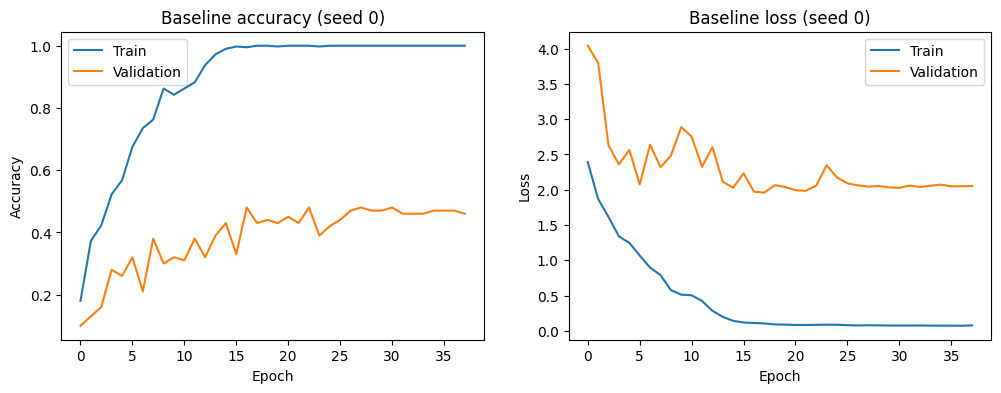

Diagnosis:
Train accuracy 100.0% vs validation accuracy 42.3%: gap of 57.7 points, the model memorizes the 400 images (overfitting).
Clean test accuracy 41.4% vs shifted test accuracy 14.4%: drop of 27.0 points, the inputs changed but the classes did not (covariate shift).
The failure is both overfitting and covariate shift.


In [13]:
h = histories[("No augmentation", 0)]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(h['accuracy'], label='Train')
plt.plot(h['val_accuracy'], label='Validation')
plt.title('Baseline accuracy (seed 0)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(h['loss'], label='Train')
plt.plot(h['val_loss'], label='Validation')
plt.title('Baseline loss (seed 0)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

tv_gap = base.train_acc.mean() - base.val_acc.mean()
cs_gap = base.clean_acc.mean() - base.shifted_acc.mean()
print("Diagnosis:")
print("Train accuracy %.1f%% vs validation accuracy %.1f%%: gap of %.1f points, the model memorizes the 400 images (overfitting)." % (
    base.train_acc.mean(), base.val_acc.mean(), tv_gap))
print("Clean test accuracy %.1f%% vs shifted test accuracy %.1f%%: drop of %.1f points, the inputs changed but the classes did not (covariate shift)." % (
    base.clean_acc.mean(), base.shifted_acc.mean(), cs_gap))
print("The failure is both overfitting and covariate shift.")

# Train the 7 configurations

In [14]:
for name in configs:
    if name == "No augmentation":
        continue
    for seed in SEEDS:
        run(name, seed)

Geometric only | seed 0 | train 37.5 | val 29.0 | clean 28.9 | shifted 16.1
Geometric only | seed 1 | train 38.8 | val 33.0 | clean 28.6 | shifted 13.2
Geometric only | seed 2 | train 71.2 | val 34.0 | clean 36.9 | shifted 13.9
Photometric only | seed 0 | train 47.2 | val 36.0 | clean 33.3 | shifted 15.9
Photometric only | seed 1 | train 85.5 | val 30.0 | clean 39.2 | shifted 16.3
Photometric only | seed 2 | train 43.2 | val 28.0 | clean 30.0 | shifted 14.6
Geometric + photometric | seed 0 | train 67.8 | val 32.0 | clean 39.2 | shifted 19.2
Geometric + photometric | seed 1 | train 87.8 | val 41.0 | clean 41.8 | shifted 18.3
Geometric + photometric | seed 2 | train 92.2 | val 36.0 | clean 43.5 | shifted 19.4
+ Cutout / Random Erasing | seed 0 | train 68.5 | val 34.0 | clean 39.0 | shifted 24.8
+ Cutout / Random Erasing | seed 1 | train 72.5 | val 33.0 | clean 40.1 | shifted 24.5
+ Cutout / Random Erasing | seed 2 | train 85.2 | val 38.0 | clean 41.2 | shifted 25.9
+ Mixup + label smooth

In [15]:
extra_results = {}

def run_variant(label, **options):
    for seed in SEEDS:
        _, _, r = train_model("Final model", seed, label=label, **options)
        extra_results[(label, seed)] = r
        print(label, "| seed", seed, "| train %.1f | val %.1f | clean %.1f | shifted %.1f" % (
            r["train_acc"], r["val_acc"], r["clean_acc"], r["shifted_acc"]))

def compare_table(labels):
    df = pd.DataFrame(list(results.values()) + list(extra_results.values()))
    df = df[df.config.isin(labels)]
    g = df.groupby("config")[["train_acc", "val_acc", "clean_acc", "shifted_acc"]]
    mean, std = g.mean().loc[labels], g.std().loc[labels]
    table = mean.round(2).astype(str) + " +- " + std.round(2).astype(str)
    table.columns = ["Train", "Validation", "Clean test", "Shifted test"]
    return mean, std, table

def plot_compare(labels, title):
    mean, std, _ = compare_table(labels)
    x = np.arange(len(labels))
    plt.figure(figsize=(10, 4.5))
    plt.bar(x - 0.2, mean["clean_acc"], 0.4, yerr=std["clean_acc"], capsize=3, label='Clean test')
    plt.bar(x + 0.2, mean["shifted_acc"], 0.4, yerr=std["shifted_acc"], capsize=3, label='Shifted test')
    plt.xticks(x, labels, rotation=20, ha='right', fontsize=8)
    plt.title(title)
    plt.xlabel('Configuration')
    plt.ylabel('Accuracy (%)')
    plt.legend()
    plt.show()

def change(a, b, column):
    mean, _, _ = compare_table([a, b])
    return mean.loc[b, column] - mean.loc[a, column]

# Part B: Augmentation strategy

### B.1 Does vertical flip help or hurt?

Horizontal + vertical flip | seed 0 | train 54.0 | val 33.0 | clean 36.0 | shifted 22.6
Horizontal + vertical flip | seed 1 | train 43.8 | val 31.0 | clean 31.2 | shifted 19.9
Horizontal + vertical flip | seed 2 | train 57.0 | val 37.0 | clean 36.1 | shifted 22.3
Final model = horizontal flip only. Accuracy % (mean +- std over 3 seeds):
                                    Train     Validation     Clean test  \
config                                                                    
Final model                 52.33 +- 4.13  32.33 +- 5.51  36.43 +- 2.29   
Horizontal + vertical flip  51.58 +- 6.95  33.67 +- 3.06  34.45 +- 2.77   

                            Shifted test  
config                                    
Final model                 22.65 +- 1.7  
Horizontal + vertical flip  21.6 +- 1.48  


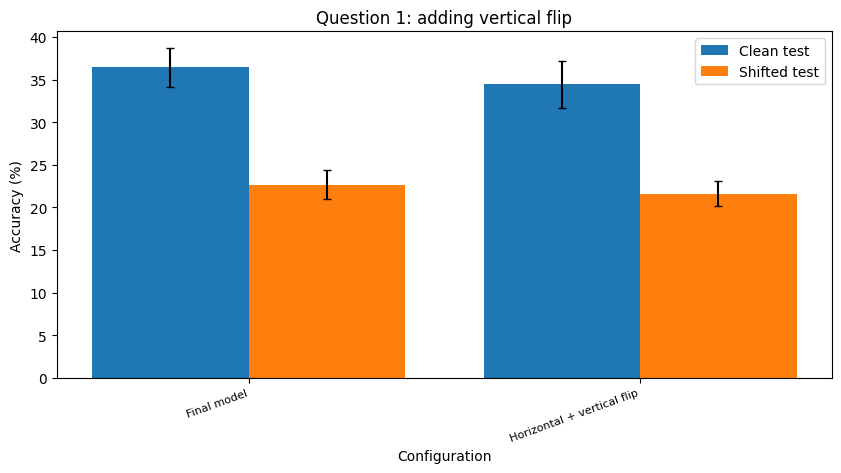


Adding vertical flip changed shifted accuracy by -1.05 points and clean accuracy by -1.98 points.
Vertical flip hurts on this dataset.
CIFAR-10 objects are almost always upright and upside-down images never appear in the test set, so these samples use up capacity without matching any test condition.


In [16]:
run_variant("Horizontal + vertical flip", aug_fn=lambda: build_aug(flip="horizontal_and_vertical"))

labels = ["Final model", "Horizontal + vertical flip"]
mean, std, table = compare_table(labels)
print("Final model = horizontal flip only. Accuracy % (mean +- std over 3 seeds):")
print(table)
plot_compare(labels, "Question 1: adding vertical flip")

d_shift = change(labels[0], labels[1], "shifted_acc")
d_clean = change(labels[0], labels[1], "clean_acc")
print("\nAdding vertical flip changed shifted accuracy by %+.2f points and clean accuracy by %+.2f points." % (d_shift, d_clean))
print("Vertical flip", "hurts" if d_shift < 0 else "did not hurt", "on this dataset.")
print("CIFAR-10 objects are almost always upright and upside-down images never appear in the test set, so these samples use up capacity without matching any test condition.")

### B.2 Rotation up to 90 degrees when the test only has 25 degrees

Rotation up to 90 degrees | seed 0 | train 61.0 | val 34.0 | clean 35.0 | shifted 23.4
Rotation up to 90 degrees | seed 1 | train 57.5 | val 34.0 | clean 33.8 | shifted 22.2
Rotation up to 90 degrees | seed 2 | train 58.5 | val 33.0 | clean 33.7 | shifted 23.3
Final model = rotation up to 25 degrees. Accuracy % (mean +- std over 3 seeds):
                                   Train     Validation     Clean test  \
config                                                                   
Final model                52.33 +- 4.13  32.33 +- 5.51  36.43 +- 2.29   
Rotation up to 90 degrees    59.0 +- 1.8  33.67 +- 0.58  34.13 +- 0.72   

                            Shifted test  
config                                    
Final model                 22.65 +- 1.7  
Rotation up to 90 degrees  22.97 +- 0.67  


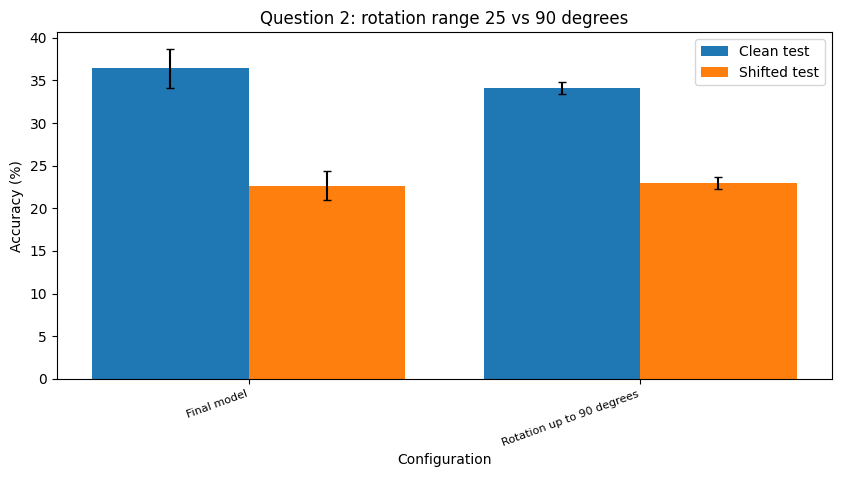


Rotation up to 90 degrees changed shifted accuracy by +0.32 points, clean accuracy by -2.30 points and training accuracy by +6.67 points.
Trade-off: the wider range adds robustness to rotation, but most training images use angles that never appear in the test, so the small model spends capacity on them.
Result: the 90 degree range did not lower shifted accuracy here.


In [17]:
run_variant("Rotation up to 90 degrees", aug_fn=lambda: build_aug(rotation=0.25))

labels = ["Final model", "Rotation up to 90 degrees"]
mean, std, table = compare_table(labels)
print("Final model = rotation up to 25 degrees. Accuracy % (mean +- std over 3 seeds):")
print(table)
plot_compare(labels, "Question 2: rotation range 25 vs 90 degrees")

d_shift = change(labels[0], labels[1], "shifted_acc")
d_clean = change(labels[0], labels[1], "clean_acc")
d_train = change(labels[0], labels[1], "train_acc")
print("\nRotation up to 90 degrees changed shifted accuracy by %+.2f points, clean accuracy by %+.2f points and training accuracy by %+.2f points." % (d_shift, d_clean, d_train))
print("Trade-off: the wider range adds robustness to rotation, but most training images use angles that never appear in the test, so the small model spends capacity on them.")
print("Result:", "the 90 degree range lowered shifted accuracy." if d_shift < 0 else "the 90 degree range did not lower shifted accuracy here.")

### B.3 Why too much augmentation reduces accuracy on a small model

Very heavy augmentation | seed 0 | train 20.0 | val 20.0 | clean 18.2 | shifted 14.3
Very heavy augmentation | seed 1 | train 18.5 | val 13.0 | clean 16.7 | shifted 13.7
Very heavy augmentation | seed 2 | train 18.0 | val 17.0 | clean 17.0 | shifted 13.8
Accuracy % (mean +- std over 3 seeds):
                                 Train     Validation     Clean test  \
config                                                                 
No augmentation           100.0 +- 0.0  42.33 +- 1.15  41.43 +- 1.18   
Final model              52.33 +- 4.13  32.33 +- 5.51  36.43 +- 2.29   
Very heavy augmentation  18.83 +- 1.04  16.67 +- 3.51  17.31 +- 0.77   

                          Shifted test  
config                                  
No augmentation          14.38 +- 0.84  
Final model               22.65 +- 1.7  
Very heavy augmentation  13.94 +- 0.33  


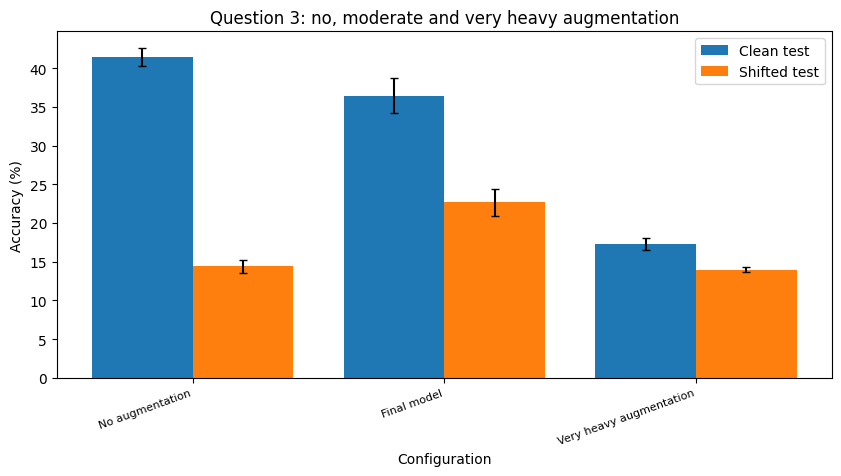


Training accuracy: none 100.0% | moderate 52.3% | very heavy 18.8%
Very heavy vs moderate augmentation: shifted accuracy -8.71 points, clean accuracy -19.12 points.
When the training accuracy drops a lot, the small model cannot fit the heavily distorted images (underfitting), so adding more augmentation stops helping.


In [18]:
run_variant("Very heavy augmentation",
            aug_fn=lambda: build_aug(rotation=0.25, shift=0.25, zoom=0.3, bright=0.5, contrast=0.6,
                                     blur_p=0.7, noise_std=30.0, noise_p=0.8, gray_p=0.3, swap_p=0.3,
                                     cut_p=1.0, cut_low=12, cut_high=24),
            mixup_prob=1.0)

labels = ["No augmentation", "Final model", "Very heavy augmentation"]
mean, std, table = compare_table(labels)
print("Accuracy % (mean +- std over 3 seeds):")
print(table)
plot_compare(labels, "Question 3: no, moderate and very heavy augmentation")

print("\nTraining accuracy: none %.1f%% | moderate %.1f%% | very heavy %.1f%%" % (
    mean.loc["No augmentation", "train_acc"], mean.loc["Final model", "train_acc"], mean.loc["Very heavy augmentation", "train_acc"]))
d_shift = change("Final model", "Very heavy augmentation", "shifted_acc")
print("Very heavy vs moderate augmentation: shifted accuracy %+.2f points, clean accuracy %+.2f points." % (
    d_shift, change("Final model", "Very heavy augmentation", "clean_acc")))
print("When the training accuracy drops a lot, the small model cannot fit the heavily distorted images (underfitting), so adding more augmentation stops helping.")

**Answers**

1. **Vertical flip:** CIFAR-10 objects are almost always upright and upside-down images do not appear in the test, so vertical flip does not match a real test condition (result in B.1). Horizontal flip is safe because a flipped car or horse keeps its class.
2. **Rotation up to 90 degrees:** it adds robustness to rotation but most training images use angles never seen in the test, so capacity is wasted on them (result in B.2). The range should match the expected shift.
3. **Too much augmentation:** a small model has limited capacity. If every image is rotated, blurred, noisy, mixed and partly erased at once, it cannot fit the training data and important details are destroyed (result in B.3).

# Part C: Regularization and training design

In [19]:
no_smoothing = dict(configs["Final model"], smoothing=0.0)

variants = [
    ("No BatchNorm", dict(use_bn=False)),
    ("Dropout after early convs", dict(dropout_place='conv')),
    ("No dropout", dict(dropout_place='none')),
    ("No L2 weight decay", dict(l2=0.0)),
    ("No label smoothing", dict(cfg=no_smoothing)),
    ("No LR scheduling", dict(use_reduce_lr=False)),
    ("No early stopping", dict(use_early_stop=False)),
]

for label, options in variants:
    run_variant(label, **options)

No BatchNorm | seed 0 | train 29.5 | val 22.0 | clean 25.7 | shifted 19.2
No BatchNorm | seed 1 | train 26.8 | val 14.0 | clean 24.3 | shifted 17.3
No BatchNorm | seed 2 | train 17.5 | val 15.0 | clean 17.0 | shifted 13.5
Dropout after early convs | seed 0 | train 36.2 | val 24.0 | clean 28.8 | shifted 18.0
Dropout after early convs | seed 1 | train 51.0 | val 28.0 | clean 35.9 | shifted 20.5
Dropout after early convs | seed 2 | train 47.0 | val 27.0 | clean 33.4 | shifted 19.4
No dropout | seed 0 | train 73.0 | val 36.0 | clean 39.2 | shifted 24.8
No dropout | seed 1 | train 53.0 | val 34.0 | clean 36.3 | shifted 22.9
No dropout | seed 2 | train 60.8 | val 30.0 | clean 36.9 | shifted 23.4
No L2 weight decay | seed 0 | train 46.5 | val 36.0 | clean 32.7 | shifted 21.3
No L2 weight decay | seed 1 | train 51.7 | val 40.0 | clean 37.9 | shifted 23.0
No L2 weight decay | seed 2 | train 48.2 | val 28.0 | clean 32.2 | shifted 20.2
No label smoothing | seed 0 | train 79.0 | val 37.0 | clean 4

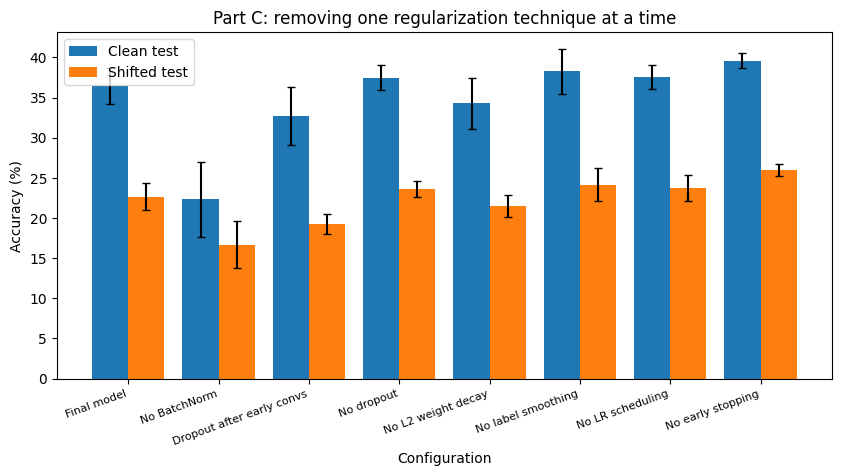

Change compared with the Final model (points):
No BatchNorm                 shifted -5.97 | clean -14.08 | validation -15.33 | train -27.75
Dropout after early convs    shifted -3.39 | clean -3.70 | validation -6.00 | train -7.58
No dropout                   shifted +1.02 | clean +1.02 | validation +1.00 | train +9.92
No L2 weight decay           shifted -1.14 | clean -2.16 | validation +2.33 | train -3.50
No label smoothing           shifted +1.52 | clean +1.85 | validation +5.67 | train +15.58
No LR scheduling             shifted +1.08 | clean +1.13 | validation +2.33 | train +8.00
No early stopping            shifted +3.32 | clean +3.15 | validation +1.33 | train +20.17

Removing 'No BatchNorm' lowers the shifted-test accuracy the most.
Dropout after the fully connected layer vs after early convolutions: +3.39 points on the shifted test.

Regularization study (accuracy %, mean +- std over 3 seeds):


,Train,Validation,Clean test,Shifted test
config,,,,
Final model,52.33 +- 4.13,32.33 +- 5.51,36.43 +- 2.29,22.65 +- 1.7
No BatchNorm,24.58 +- 6.29,17.0 +- 4.36,22.35 +- 4.67,16.68 +- 2.93
Dropout after early convs,44.75 +- 7.63,26.33 +- 2.08,32.74 +- 3.6,19.26 +- 1.26
No dropout,62.25 +- 10.08,33.33 +- 3.06,37.46 +- 1.57,23.67 +- 1.0
No L2 weight decay,48.83 +- 2.67,34.67 +- 6.11,34.27 +- 3.13,21.51 +- 1.41
No label smoothing,67.92 +- 13.42,38.0 +- 1.73,38.29 +- 2.81,24.17 +- 2.07
No LR scheduling,60.33 +- 11.38,34.67 +- 2.89,37.56 +- 1.49,23.73 +- 1.61
No early stopping,72.5 +- 3.0,33.67 +- 0.58,39.59 +- 0.96,25.97 +- 0.7


In [20]:
labels = ["Final model"] + [v[0] for v in variants]
mean, std, table = compare_table(labels)
plot_compare(labels, "Part C: removing one regularization technique at a time")

print("Change compared with the Final model (points):")
for label, _ in variants:
    print("%-28s shifted %+.2f | clean %+.2f | validation %+.2f | train %+.2f" % (
        label,
        change("Final model", label, "shifted_acc"), change("Final model", label, "clean_acc"),
        change("Final model", label, "val_acc"), change("Final model", label, "train_acc")))

worst = min(variants, key=lambda v: change("Final model", v[0], "shifted_acc"))[0]
print("\nRemoving '%s' lowers the shifted-test accuracy the most." % worst)
placement = change("Dropout after early convs", "Final model", "shifted_acc")
print("Dropout after the fully connected layer vs after early convolutions: %+.2f points on the shifted test." % placement)
print("\nRegularization study (accuracy %, mean +- std over 3 seeds):")
table

| Technique | Where | Why there |
|---|---|---|
| BatchNorm | after every convolution | stable training from scratch, small regularizing effect |
| Dropout | after the fully connected layer | the dense layer is where the model memorizes; dropping channels between early convolutions damages the spatial feature maps |
| Global average pooling | before the Dense layer | far fewer parameters than flattening |
| L2 weight decay (5e-5) | conv and Dense weights | keeps weights small |
| ReduceLROnPlateau | callback on validation loss | smaller steps when learning stalls |
| EarlyStopping (best weights restored) | callback on validation loss | stops when validation loss no longer improves |
| Label smoothing 0.1 | loss | avoids over-confident predictions, works well with mixup |



# Part D: Ablation study

In [21]:
all_results = pd.DataFrame(list(results.values()))
all_results.to_csv("results_all_runs.csv", index=False)

order = list(configs.keys())
mean = all_results.groupby("config")[["train_acc", "val_acc", "clean_acc", "shifted_acc"]].mean().loc[order]
std = all_results.groupby("config")[["train_acc", "val_acc", "clean_acc", "shifted_acc"]].std().loc[order]

table = pd.DataFrame({
    "Val Acc":      mean["val_acc"].round(2).astype(str) + " +- " + std["val_acc"].round(2).astype(str),
    "Clean Test":   mean["clean_acc"].round(2).astype(str) + " +- " + std["clean_acc"].round(2).astype(str),
    "Shifted Test": mean["shifted_acc"].round(2).astype(str) + " +- " + std["shifted_acc"].round(2).astype(str),
})
print("Ablation table (accuracy %, mean +- std over 3 seeds)")
table

Ablation table (accuracy %, mean +- std over 3 seeds)


,Val Acc,Clean Test,Shifted Test
config,,,
No augmentation,42.33 +- 1.15,41.43 +- 1.18,14.38 +- 0.84
Geometric only,32.0 +- 2.65,31.48 +- 4.68,14.41 +- 1.52
Photometric only,31.33 +- 4.16,34.19 +- 4.69,15.61 +- 0.92
Geometric + photometric,36.33 +- 4.51,41.47 +- 2.16,18.97 +- 0.55
+ Cutout / Random Erasing,35.0 +- 2.65,40.11 +- 1.11,25.07 +- 0.78
+ Mixup + label smoothing,33.67 +- 3.51,37.91 +- 2.14,23.63 +- 1.63
Final model,32.33 +- 5.51,36.43 +- 2.29,22.65 +- 1.7


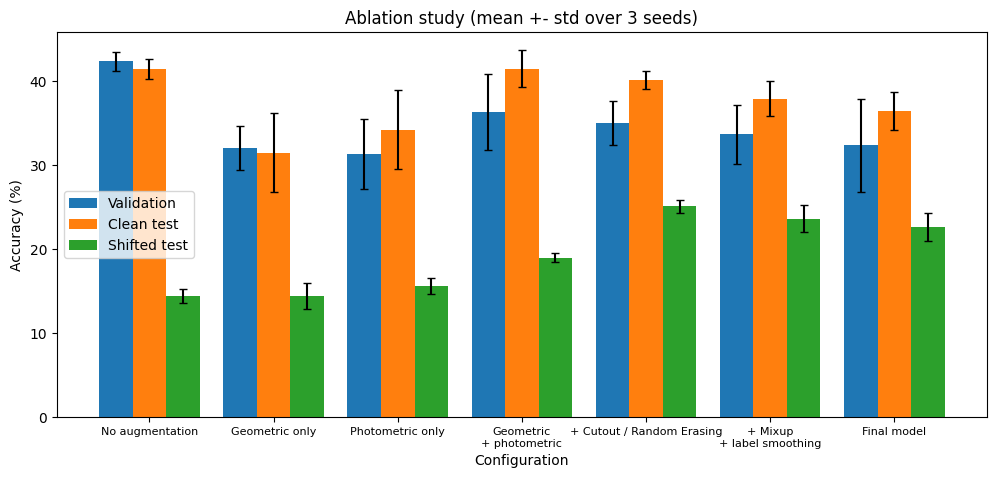

Gain on shifted test compared with the row above:
config
No augmentation               NaN
Geometric only               0.03
Photometric only             1.20
Geometric + photometric      3.36
+ Cutout / Random Erasing    6.10
+ Mixup + label smoothing   -1.44
Final model                 -0.98
Name: shifted_acc, dtype: float64

Largest gain on the shifted test: '+ Cutout / Random Erasing' (+6.10 points), which matches the random rectangular occlusion.
Geometric only vs baseline: +0.03 points
Photometric only vs baseline: +1.23 points
Clean test accuracy: baseline 41.4% -> final model 36.4%
Shifted test accuracy: baseline 14.4% -> final model 22.7%


In [22]:
x = np.arange(len(order))
plt.figure(figsize=(12, 5))
plt.bar(x - 0.27, mean["val_acc"], 0.27, yerr=std["val_acc"], capsize=3, label='Validation')
plt.bar(x,        mean["clean_acc"], 0.27, yerr=std["clean_acc"], capsize=3, label='Clean test')
plt.bar(x + 0.27, mean["shifted_acc"], 0.27, yerr=std["shifted_acc"], capsize=3, label='Shifted test')
plt.xticks(x, [o.replace(" + ", "\n+ ") for o in order], fontsize=8)
plt.title('Ablation study (mean +- std over 3 seeds)')
plt.xlabel('Configuration')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.show()

shifted_mean = mean["shifted_acc"]
gain = shifted_mean.diff()
print("Gain on shifted test compared with the row above:")
print(gain.round(2))

targets = {
    "Geometric only": "the rotation",
    "Photometric only": "the brightness, contrast, blur and noise changes",
    "Geometric + photometric": "rotation together with the photometric changes",
    "+ Cutout / Random Erasing": "the random rectangular occlusion",
    "+ Mixup + label smoothing": "over-confidence on the tiny training set",
    "Final model": "the hidden grayscale / channel-swap corruption",
}
best_step = gain.iloc[1:].idxmax()
print("\nLargest gain on the shifted test: '%s' (%+.2f points), which matches %s." % (best_step, gain[best_step], targets[best_step]))
print("Geometric only vs baseline: %+.2f points" % (shifted_mean["Geometric only"] - shifted_mean["No augmentation"]))
print("Photometric only vs baseline: %+.2f points" % (shifted_mean["Photometric only"] - shifted_mean["No augmentation"]))
print("Clean test accuracy: baseline %.1f%% -> final model %.1f%%" % (mean["clean_acc"]["No augmentation"], mean["clean_acc"]["Final model"]))
print("Shifted test accuracy: baseline %.1f%% -> final model %.1f%%" % (shifted_mean["No augmentation"], shifted_mean["Final model"]))

# Part E: Error analysis (Final model, seed 0)

Classification report on shifted_test:

              precision    recall  f1-score   support

    airplane       0.34      0.21      0.26      1000
  automobile       0.28      0.25      0.26      1000
        bird       0.19      0.09      0.12      1000
         cat       0.18      0.20      0.19      1000
        deer       0.20      0.24      0.22      1000
         dog       0.24      0.20      0.21      1000
        frog       0.21      0.37      0.27      1000
       horse       0.23      0.29      0.26      1000
        ship       0.42      0.16      0.23      1000
       truck       0.27      0.39      0.32      1000

    accuracy                           0.24     10000
   macro avg       0.26      0.24      0.23     10000
weighted avg       0.26      0.24      0.23     10000



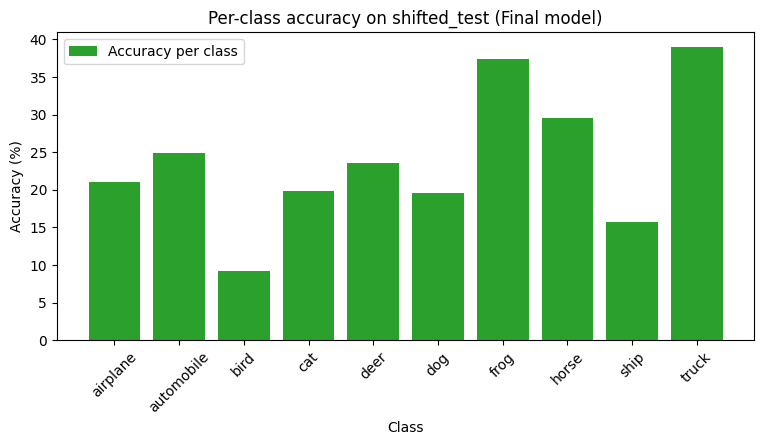

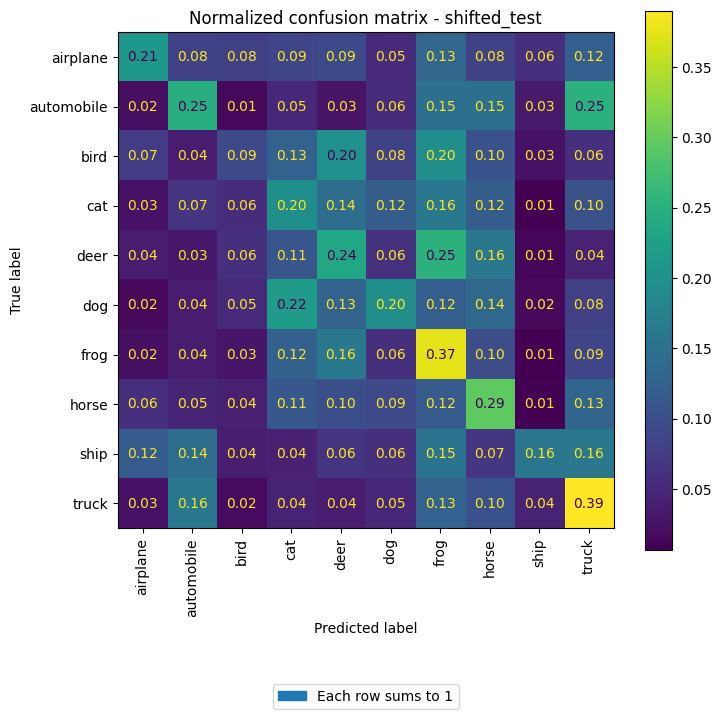

Most confused (true -> predicted):
deer -> frog 0.25
automobile -> truck 0.25
dog -> cat 0.22
bird -> deer 0.2
bird -> frog 0.2
cat -> frog 0.16

Best class: truck (39.0%) | Worst class: bird (9.2%)
These pairs have similar shapes, colours and backgrounds at 32x32 pixels, and blur, noise and occlusion remove the small details (ears, legs, wheels) that separate them.


In [23]:
final_model = all_models[("Final model", 0)]
pred = np.argmax(final_model.predict(X_shifted_test, batch_size=500, verbose=0), axis=1)

print("Classification report on shifted_test:\n")
print(classification_report(y_shifted_test, pred, target_names=class_names))

cm = confusion_matrix(y_shifted_test, pred, normalize='true')
per_class = np.diag(cm) * 100

plt.figure(figsize=(9, 4))
plt.bar(class_names, per_class, label='Accuracy per class', color='tab:green')
plt.title('Per-class accuracy on shifted_test (Final model)')
plt.xlabel('Class')
plt.ylabel('Accuracy (%)')
plt.xticks(rotation=45)
plt.legend()
plt.show()

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation='vertical', values_format='.2f')
ax.set_title("Normalized confusion matrix - shifted_test")
ax.legend(handles=[Patch(color='tab:blue', label='Each row sums to 1')], loc='upper center', bbox_to_anchor=(0.5, -0.3))
plt.show()

pairs = []
for i in range(10):
    for j in range(10):
        if i != j:
            pairs.append((cm[i, j], class_names[i], class_names[j]))
print("Most confused (true -> predicted):")
for value, a, b in sorted(pairs, reverse=True)[:6]:
    print(a, "->", b, round(value, 2))
print("\nBest class: %s (%.1f%%) | Worst class: %s (%.1f%%)" % (
    class_names[np.argmax(per_class)], per_class.max(), class_names[np.argmin(per_class)], per_class.min()))
print("These pairs have similar shapes, colours and backgrounds at 32x32 pixels, and blur, noise and occlusion remove the small details (ears, legs, wheels) that separate them.")

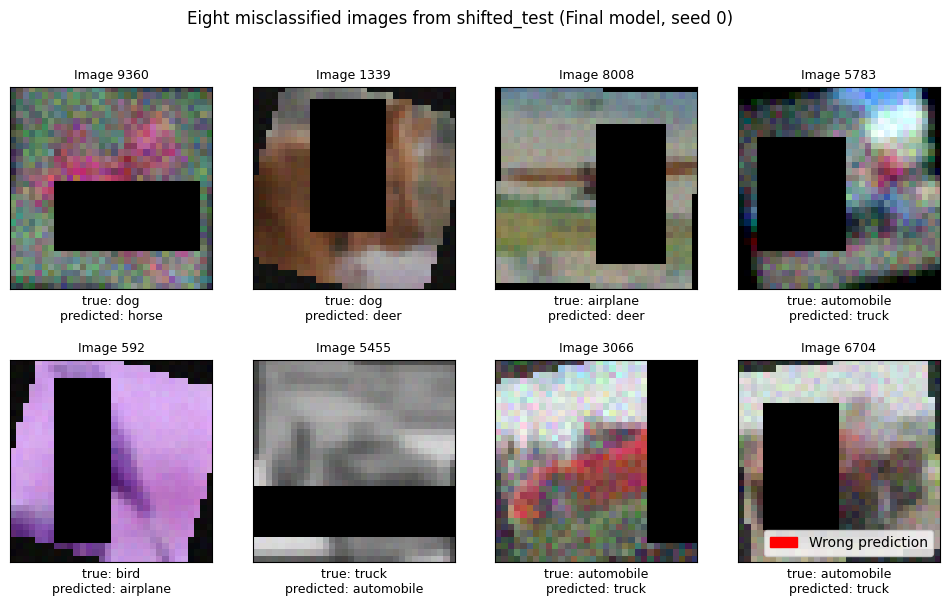

In [24]:
wrong = np.where(pred != y_shifted_test)[0]
chosen = np.random.RandomState(SEED).choice(wrong, 8, replace=False)

plt.figure(figsize=(12, 6.5))
for k, i in enumerate(chosen):
    plt.subplot(2, 4, k + 1)
    plt.imshow(X_shifted_test[i].astype('uint8'))
    plt.title("Image " + str(i), fontsize=9)
    plt.xlabel("true: " + class_names[y_shifted_test[i]] + "\npredicted: " + class_names[pred[i]], fontsize=9)
    plt.xticks([])
    plt.yticks([])
plt.suptitle("Eight misclassified images from shifted_test (Final model, seed 0)")
plt.legend(handles=[Patch(color='red', label='Wrong prediction')], loc='lower right')
plt.show()

**E.3 Why each image failed:**

| Image | True -> Predicted | Visual reason |
|---|---|---|
| 1 | | |
| 2 | | |
| 3 | | |
| 4 | | |
| 5 | | |
| 6 | | |
| 7 | | |
| 8 | | |

Accuracy % with only the hidden corruption (mean and std over 3 seeds):
                         clean       hidden_only      
                          mean   std        mean   std
config                                                
No augmentation          41.43  1.18       38.34  1.03
Geometric + photometric  41.47  2.16       36.19  1.77
Final model              36.43  2.29       32.55  3.23


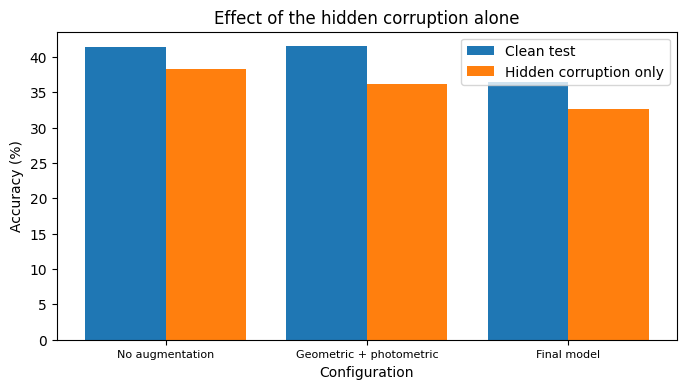


E.4 Discussion:
No augmentation            clean 41.43% -> hidden only 38.34% (drop 3.09 points, 7.5% of its clean accuracy)
Geometric + photometric    clean 41.47% -> hidden only 36.19% (drop 5.28 points, 12.7% of its clean accuracy)
Final model                clean 36.43% -> hidden only 32.55% (drop 3.88 points, 10.7% of its clean accuracy)
A smaller drop for the final model means the colour augmentation (grayscale and reversed channels) generalized to the hidden corruption.
The test also uses other channel orders that training never shows, so a part of the hidden corruption is still unseen.


In [25]:
names = ["No augmentation", "Geometric + photometric", "Final model"]
hidden_rows = []
for name in names:
    for seed in SEEDS:
        m = all_models[(name, seed)]
        hidden_rows.append({"config": name,
                            "clean": accuracy(m, X_clean_test, y_clean_test),
                            "hidden_only": accuracy(m, X_hidden_test, y_hidden_test)})
hidden_table = pd.DataFrame(hidden_rows).groupby("config").agg(["mean", "std"]).loc[names].round(2)
print("Accuracy % with only the hidden corruption (mean and std over 3 seeds):")
print(hidden_table)

hm = hidden_table.xs("mean", axis=1, level=1)
x = np.arange(3)
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, hm["clean"], 0.4, label='Clean test')
plt.bar(x + 0.2, hm["hidden_only"], 0.4, label='Hidden corruption only')
plt.xticks(x, names, fontsize=8)
plt.title('Effect of the hidden corruption alone')
plt.xlabel('Configuration')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.show()

print("\nE.4 Discussion:")
for n in names:
    drop = hm.loc[n, "clean"] - hm.loc[n, "hidden_only"]
    print("%-26s clean %.2f%% -> hidden only %.2f%% (drop %.2f points, %.1f%% of its clean accuracy)" % (
        n, hm.loc[n, "clean"], hm.loc[n, "hidden_only"], drop, 100 * drop / hm.loc[n, "clean"]))
print("A smaller drop for the final model means the colour augmentation (grayscale and reversed channels) generalized to the hidden corruption.")
print("The test also uses other channel orders that training never shows, so a part of the hidden corruption is still unseen.")

# Part F: Test-time augmentation

In [26]:
def shift_images(X, dx, dy):
    padded = np.pad(X, ((0, 0), (3, 3), (3, 3), (0, 0)))
    return padded[:, 3 + dy:35 + dy, 3 + dx:35 + dx]

def predict_tta(model, X):
    versions = [X,
                X[:, :, ::-1],
                shift_images(X, 2, 0), shift_images(X, -2, 0),
                shift_images(X, 0, 2), shift_images(X, 0, -2),
                shift_images(X[:, :, ::-1], 2, 2), shift_images(X[:, :, ::-1], -2, -2)]
    probs = 0
    for v in versions:
        probs = probs + model.predict(np.ascontiguousarray(v), batch_size=500, verbose=0)
    return probs / len(versions), len(versions)

tta_rows = []
for seed in SEEDS:
    m = all_models[("Final model", seed)]
    m.predict(X_shifted_test[:100], verbose=0)

    t = time.time()
    p_normal = m.predict(X_shifted_test, batch_size=500, verbose=0)
    time_normal = time.time() - t

    t = time.time()
    p_tta, n_versions = predict_tta(m, X_shifted_test)
    time_tta = time.time() - t

    tta_rows.append({"seed": seed,
                     "without_TTA": np.mean(np.argmax(p_normal, 1) == y_shifted_test) * 100,
                     "with_TTA": np.mean(np.argmax(p_tta, 1) == y_shifted_test) * 100,
                     "time_normal_s": time_normal, "time_TTA_s": time_tta})

tta = pd.DataFrame(tta_rows)
print(tta.round(3))
print("\nShifted-test accuracy without TTA: %.2f +- %.2f" % (tta.without_TTA.mean(), tta.without_TTA.std()))
print("Shifted-test accuracy with TTA (%d versions): %.2f +- %.2f" % (n_versions, tta.with_TTA.mean(), tta.with_TTA.std()))
print("Change: %+.2f points" % (tta.with_TTA.mean() - tta.without_TTA.mean()))
print("Inference cost: %d forward passes per image, measured time x%.1f" % (n_versions, tta.time_TTA_s.mean() / tta.time_normal_s.mean()))

   seed  without_TTA  with_TTA  time_normal_s  time_TTA_s
0     0        23.98     24.05          0.802       9.100
1     1        23.23     22.72          0.847       8.443
2     2        20.74     20.92          0.954       8.635

Shifted-test accuracy without TTA: 22.65 +- 1.70
Shifted-test accuracy with TTA (8 versions): 22.56 +- 1.57
Change: -0.09 points
Inference cost: 8 forward passes per image, measured time x10.1


# Final summary

In [27]:
final = all_results[all_results.config == "Final model"]
print("Seeds used:", SEEDS, "| main seed:", SEED)
print("Train accuracy:              %.2f +- %.2f %%" % (final.train_acc.mean(), final.train_acc.std()))
print("Validation accuracy:         %.2f +- %.2f %%" % (final.val_acc.mean(), final.val_acc.std()))
print("Final clean test accuracy:   %.2f +- %.2f %%" % (final.clean_acc.mean(), final.clean_acc.std()))
print("Final shifted test accuracy: %.2f +- %.2f %%" % (final.shifted_acc.mean(), final.shifted_acc.std()))
print("Baseline shifted accuracy:   %.2f %%" % shifted_mean["No augmentation"])
print("Configuration:", configs["Final model"], "| learning rate:", LR, "| dropout:", DROPOUT)
print("Parameters:", n_params)
print("Single change that helped most:", best_step, "(%+.2f points)" % gain[best_step])

Seeds used: [0, 1, 2] | main seed: 42
Train accuracy:              52.33 +- 4.13 %
Validation accuracy:         32.33 +- 5.51 %
Final clean test accuracy:   36.43 +- 2.29 %
Final shifted test accuracy: 22.65 +- 1.70 %
Baseline shifted accuracy:   14.38 %
Configuration: {'geometric': 1, 'photometric': 1, 'colour': 1, 'cutout': 1, 'mixup': 1, 'smoothing': 0.1} | learning rate: 0.003 | dropout: 0.2
Parameters: 271578
Single change that helped most: + Cutout / Random Erasing (+6.10 points)
